# Mission 4 · 결과 분석 (최종 모델 R50)

학습은 하지 않고, 저장된 OOF 예측으로 분석한다. OOF는 각 이미지가 학습에 쓰이지 않은 fold 모델로 예측한 값이므로, train 5,216장 전체를 공정하게 평가할 수 있다.

* Before: Baseline CNN을 같은 5-fold로 학습한 B5
* After: 최종 모델 R50 (ResNet50, 여백 크롭, 5-fold)
* 비교 모델: C1(ResNet18), D1(DenseNet121), EB0(EfficientNet-B0)

## 1. 환경 설정과 데이터 로드

이미지는 최종 모델과 같은 전처리(여백 크롭 후 letterbox 224)로 불러와 실패 사례를 보여 줄 때 쓴다.

In [1]:
import os, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from matplotlib import font_manager
for _f in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if _f in {f.name for f in font_manager.fontManager.ttflist}: plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

D = next(p for p in ["../../data"] if os.path.exists(os.path.join(p, "train.csv")))
os.makedirs("../../analysis/m4", exist_ok=True)
tr = pd.read_csv(os.path.join(D, "train.csv")); y = tr.label.astype(int).values
CLASSES = ["NORMAL", "PNEUMONIA"]
OOF = {"Baseline(B5)": np.load("../../outputs/oof_B5.npy"), "C1 ResNet18": np.load("../../outputs/oof_C1.npy"),
       "D1 DenseNet121": np.load("../../outputs/oof_D1.npy"), "EB0 EfficientNet-B0": np.load("../../outputs/oof_EB0.npy"),
       "R50 ResNet50 (최종)": np.load("../../outputs/oof_R50.npy")}
R = OOF["R50 ResNet50 (최종)"]; B = OOF["Baseline(B5)"]

def crop_content(img, T=10):
    a = np.asarray(img.convert("L")); r, c = np.where(a > T)
    return img if len(r) == 0 else img.crop((c.min(), r.min(), c.max() + 1, r.max() + 1))
def letterbox(img, size=224):
    img = img.convert("L"); w, h = img.size; s = size / max(w, h)
    nw, nh = max(1, round(w * s)), max(1, round(h * s))
    c = Image.new("L", (size, size), 0); c.paste(img.resize((nw, nh), Image.BILINEAR), ((size - nw) // 2, (size - nh) // 2)); return c
def load(i): return np.asarray(letterbox(crop_content(Image.open(os.path.join(D, "train", tr.file_name[i])))))
print("OOF 파일:", {k: v.shape for k, v in OOF.items()})

OOF 파일: {'Baseline(B5)': (5216,), 'C1 ResNet18': (5216,), 'D1 DenseNet121': (5216,), 'EB0 EfficientNet-B0': (5216,), 'R50 ResNet50 (최종)': (5216,)}


## 2. Before vs After: 혼동행렬과 지표

* 민감도(Sensitivity): 실제 폐렴 중 폐렴으로 찾은 비율. 낮으면 환자를 놓친다.
* 특이도(Specificity): 실제 정상 중 정상으로 판정한 비율. 낮으면 불필요한 추가 검사가 늘어난다.
* PPV(양성 예측도): 폐렴이라고 판정한 것 중 실제 폐렴 비율. NPV(음성 예측도): 정상이라고 판정한 것 중 실제 정상 비율.

                        정확도     AUC     민감도     특이도     PPV     NPV      TP     FN     FP      TN
Baseline(B5)         0.9507  0.9868  0.9636  0.9135  0.9699  0.8968  3734.0  141.0  116.0  1225.0
C1 ResNet18          0.9877  0.9991  0.9868  0.9903  0.9966  0.9630  3824.0   51.0   13.0  1328.0
D1 DenseNet121       0.9887  0.9981  0.9902  0.9843  0.9946  0.9720  3837.0   38.0   21.0  1320.0
EB0 EfficientNet-B0  0.9877  0.9992  0.9868  0.9903  0.9966  0.9630  3824.0   51.0   13.0  1328.0
R50 ResNet50 (최종)    0.9875  0.9985  0.9881  0.9858  0.9951  0.9664  3829.0   46.0   19.0  1322.0


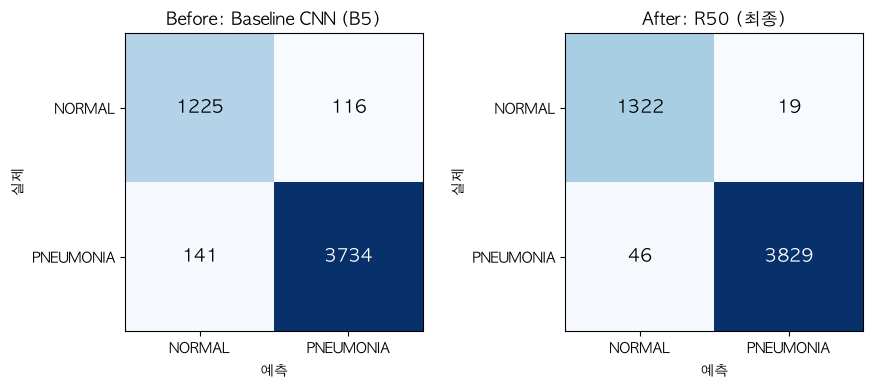

In [2]:
def metrics(p, thr=0.5):
    pr = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pr).ravel()
    return dict(정확도=accuracy_score(y, pr), AUC=roc_auc_score(y, p), 민감도=tp/(tp+fn), 특이도=tn/(tn+fp),
                PPV=tp/(tp+fp), NPV=tn/(tn+fn), TP=tp, FN=fn, FP=fp, TN=tn)
mt = pd.DataFrame({k: metrics(v) for k, v in OOF.items()}).T
print(mt.round(4).to_string())
mt.round(4).to_csv("../../analysis/m4/metrics_oof.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, p) in zip(axes, [("Before: Baseline CNN (B5)", B), ("After: R50 (최종)", R)]):
    cm = confusion_matrix(y, (p >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], CLASSES); ax.set_yticks([0, 1], CLASSES); ax.set_xlabel("예측"); ax.set_ylabel("실제"); ax.set_title(name)
plt.tight_layout(); plt.savefig("../../analysis/m4/confusion_before_after.png", dpi=110); plt.show()

## 3. 임계값에 따른 민감도와 특이도 (최종 모델, OOF)

임계값을 바꾸면 민감도와 특이도가 서로 반대로 움직인다. 이 표는 OOF로만 계산하며, test 결과로 임계값을 고르지 않는다.

In [3]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = metrics(R, t); rows.append(dict(임계값=t, 정확도=m["정확도"], 민감도=m["민감도"], 특이도=m["특이도"], FN=m["FN"], FP=m["FP"]))
thr = pd.DataFrame(rows); print(thr.round(4).to_string(index=False)); thr.round(4).to_csv("../../analysis/m4/threshold_R50.csv", index=False, encoding="utf-8-sig")

 임계값    정확도    민감도    특이도  FN  FP
 0.1 0.9854 0.9969 0.9523  12  64
 0.2 0.9875 0.9935 0.9702  25  40
 0.3 0.9893 0.9923 0.9806  30  26
 0.4 0.9889 0.9910 0.9828  35  23
 0.5 0.9875 0.9881 0.9858  46  19
 0.6 0.9849 0.9832 0.9896  65  14
 0.7 0.9827 0.9791 0.9933  81   9
 0.8 0.9783 0.9724 0.9955 107   6
 0.9 0.9576 0.9432 0.9993 220   1


## 4. 예측 확률 분포와 오류의 확신도

오류가 0.5 근처의 애매한 이미지에서 나는지, 높은 확신으로 틀리는지 확인한다. 확신이 높은 오류는 임계값 조정으로 고치기 어렵다.

놓친 폐렴(FN) 46 장의 폐렴 확률 구간:
 (-0.001, 0.1]    12
(0.1, 0.3]       18
(0.3, 0.5]       16
(0.5, 0.7]        0
(0.7, 0.9]        0
(0.9, 1.0]        0

정상 오판정(FP) 19 장의 폐렴 확률 구간:
 (-0.001, 0.1]     0
(0.1, 0.3]        0
(0.3, 0.5]        0
(0.5, 0.7]       10
(0.7, 0.9]        8
(0.9, 1.0]        1


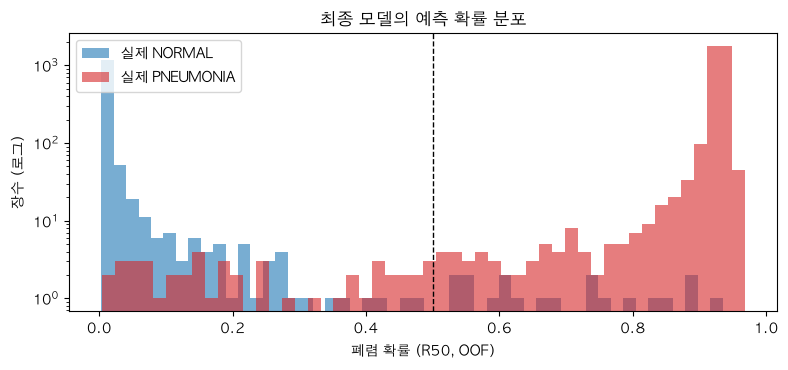

In [4]:
pred = (R >= 0.5).astype(int)
fn_idx = np.where((y == 1) & (pred == 0))[0]; fp_idx = np.where((y == 0) & (pred == 1))[0]
def band(p):
    return pd.cut(p, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], include_lowest=True).value_counts().sort_index()
print("놓친 폐렴(FN)", len(fn_idx), "장의 폐렴 확률 구간:\n", band(R[fn_idx]).to_string())
print("\n정상 오판정(FP)", len(fp_idx), "장의 폐렴 확률 구간:\n", band(R[fp_idx]).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(R[y == 0], bins=50, alpha=0.6, label="실제 NORMAL", color="tab:blue")
ax.hist(R[y == 1], bins=50, alpha=0.6, label="실제 PNEUMONIA", color="tab:red")
ax.axvline(0.5, color="k", ls="--", lw=1); ax.set_yscale("log"); ax.set_xlabel("폐렴 확률 (R50, OOF)"); ax.set_ylabel("장수 (로그)")
ax.set_title("최종 모델의 예측 확률 분포"); ax.legend(); plt.tight_layout(); plt.savefig("../../analysis/m4/prob_hist_R50.png", dpi=110); plt.show()

## 5. 실패 사례 이미지

확신이 가장 높았던 오류부터 보여 준다. 위 줄은 놓친 폐렴(FN), 아래 줄은 정상 오판정(FP)이다.

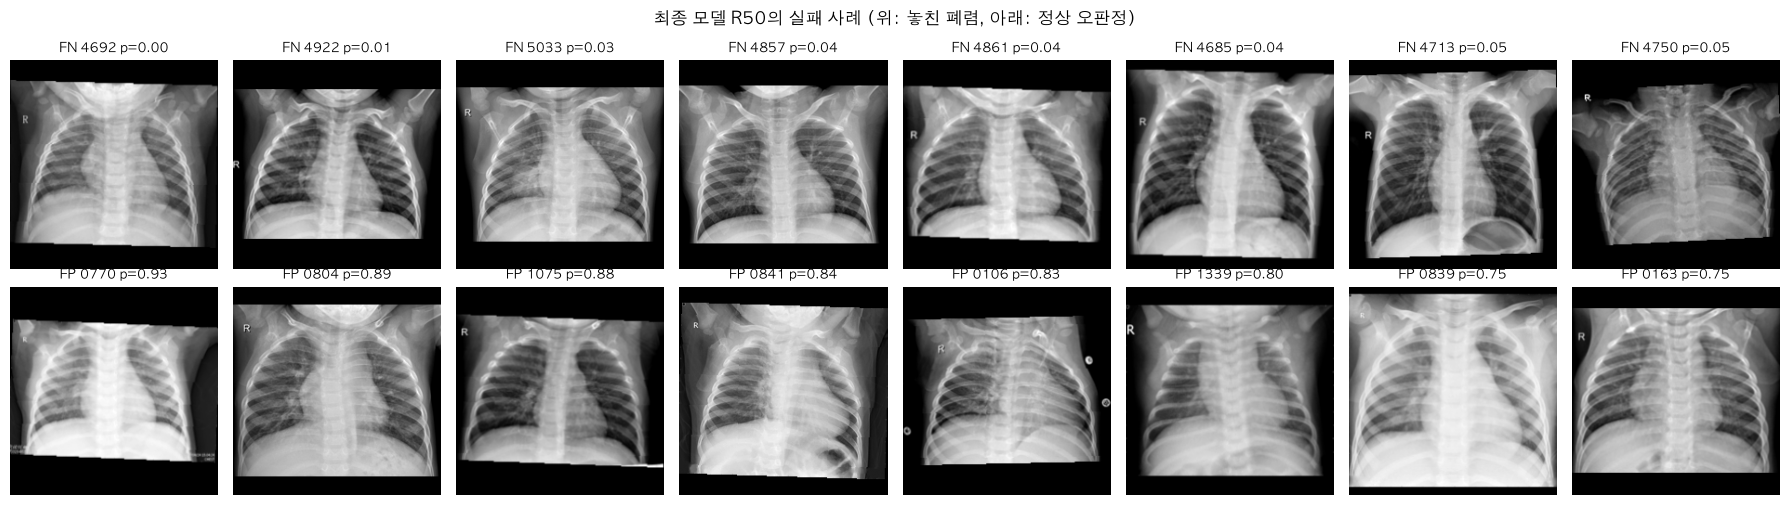

In [5]:
show_fn = fn_idx[np.argsort(R[fn_idx])][:8]; show_fp = fp_idx[np.argsort(-R[fp_idx])][:8]
fig, axes = plt.subplots(2, 8, figsize=(18, 5.2))
for ax, i in zip(axes[0], show_fn): ax.imshow(load(i), cmap="gray"); ax.axis("off"); ax.set_title(f"FN {tr.file_name[i][6:10]} p={R[i]:.2f}", fontsize=9)
for ax, i in zip(axes[1], show_fp): ax.imshow(load(i), cmap="gray"); ax.axis("off"); ax.set_title(f"FP {tr.file_name[i][6:10]} p={R[i]:.2f}", fontsize=9)
plt.suptitle("최종 모델 R50의 실패 사례 (위: 놓친 폐렴, 아래: 정상 오판정)"); plt.tight_layout(); plt.savefig("../../analysis/m4/failure_cases_R50.png", dpi=105); plt.show()

## 6. 여러 모델이 공통으로 틀린 이미지

구조가 다른 네 모델(C1, D1, EB0, R50)이 모두 틀린 이미지는 모델 구조와 관계없이 어려운 이미지이다.

네 모델 중 틀린 모델 수별 장수: {0: 5097, 1: 53, 2: 26, 3: 13, 4: 27}
네 모델 모두 틀림: 27 장 | 실제 NORMAL 4 | 실제 PNEUMONIA 23


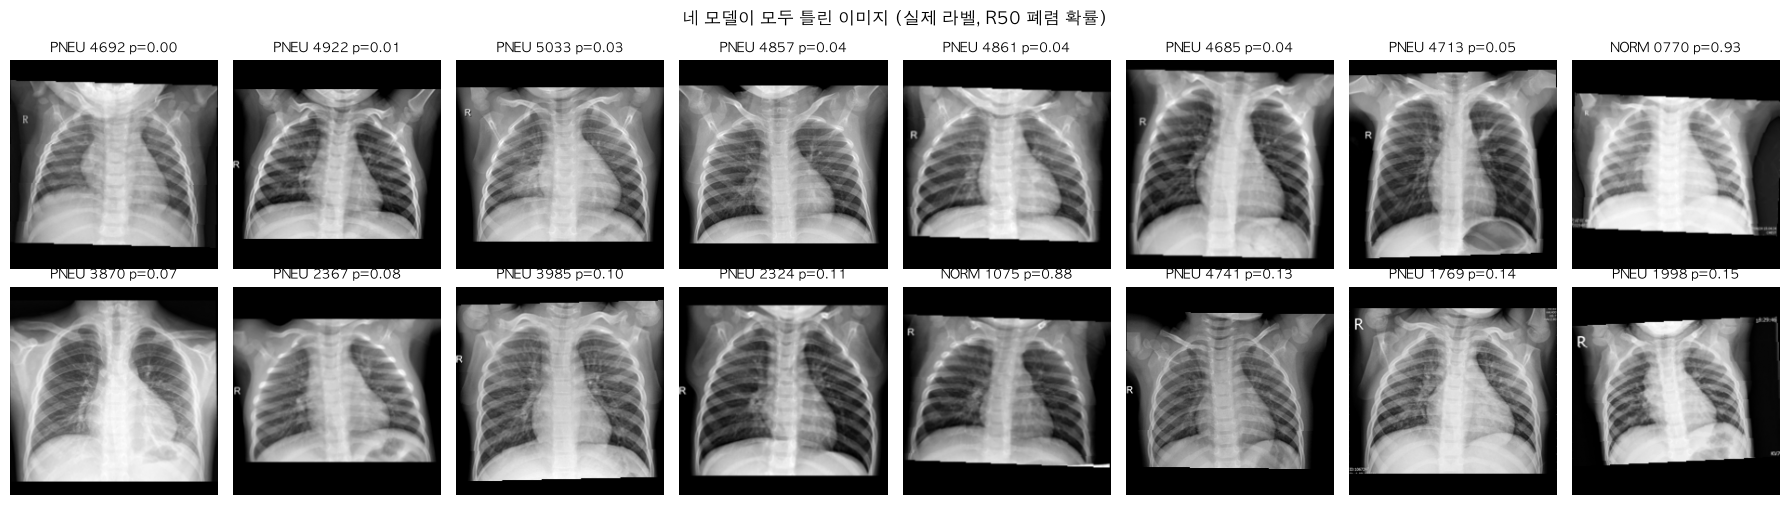

In [6]:
names = ["C1 ResNet18", "D1 DenseNet121", "EB0 EfficientNet-B0", "R50 ResNet50 (최종)"]
wrong = np.stack([((OOF[n] >= 0.5).astype(int) != y) for n in names])
nwrong = wrong.sum(0)
common = np.where(nwrong == 4)[0]
print("네 모델 중 틀린 모델 수별 장수:", {k: int((nwrong == k).sum()) for k in range(5)})
print("네 모델 모두 틀림:", len(common), "장 | 실제 NORMAL", int((y[common] == 0).sum()), "| 실제 PNEUMONIA", int((y[common] == 1).sum()))
pd.DataFrame({"file_name": tr.file_name[common].values, "실제": [CLASSES[v] for v in y[common]],
              **{n: OOF[n][common].round(3) for n in names}}).to_csv("../../analysis/m4/common_errors_4models.csv", index=False, encoding="utf-8-sig")
sel = common[np.argsort(-np.abs(R[common] - 0.5))][:16]
fig, axes = plt.subplots(2, 8, figsize=(18, 5.2))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(load(i), cmap="gray"); ax.axis("off"); ax.set_title(f"{CLASSES[y[i]][:4]} {tr.file_name[i][6:10]} p={R[i]:.2f}", fontsize=9)
plt.suptitle("네 모델이 모두 틀린 이미지 (실제 라벨, R50 폐렴 확률)"); plt.tight_layout(); plt.savefig("../../analysis/m4/common_errors_4models.png", dpi=105); plt.show()

## 7. 오류 이미지의 정량적 특징

오류 이미지가 같은 클래스의 맞힌 이미지와 어떻게 다른지 밝기, 대비, 내용 비율로 비교한다. Mann-Whitney U 검정으로 차이가 우연인지 확인한다.

* 평균 밝기: 내용 영역(검은 여백 제외)의 평균 밝기
* 대비: 내용 영역 밝기의 표준편차
* 폐 영역 밝기: 이미지 가운데 위쪽 영역(폐가 주로 있는 곳)의 평균 밝기

In [7]:
def feats(i):
    a = load(i).astype(np.float32); m = a > 10; body = a[m]
    h, w = a.shape; lung = a[int(h * 0.25):int(h * 0.65), int(w * 0.15):int(w * 0.85)]
    return dict(평균밝기=body.mean(), 대비=body.std(), 폐영역밝기=lung[lung > 10].mean(), 내용비율=m.mean())
tn_idx = np.where((y == 0) & (pred == 0))[0]; tp_idx = np.where((y == 1) & (pred == 1))[0]
rng = np.random.default_rng(0)
groups = {"정상 오판정(FP)": fp_idx, "정상 맞힘(TN, 표본 300)": rng.choice(tn_idx, 300, replace=False),
          "놓친 폐렴(FN)": fn_idx, "폐렴 맞힘(TP, 표본 300)": rng.choice(tp_idx, 300, replace=False)}
F = {g: pd.DataFrame([feats(i) for i in idx]) for g, idx in groups.items()}
summary = pd.DataFrame({g: f.median() for g, f in F.items()}).T.round(3)
print(summary.to_string())
for a, b in [("정상 오판정(FP)", "정상 맞힘(TN, 표본 300)"), ("놓친 폐렴(FN)", "폐렴 맞힘(TP, 표본 300)")]:
    print(f"\n{a} vs {b} (Mann-Whitney p):", {c: round(mannwhitneyu(F[a][c], F[b][c]).pvalue, 4) for c in F[a].columns})
summary.to_csv("../../analysis/m4/error_features.csv", encoding="utf-8-sig")

                      평균밝기      대비    폐영역밝기   내용비율
정상 오판정(FP)         137.032  48.893  141.225  0.726
정상 맞힘(TN, 표본 300)  133.970  49.942  135.640  0.762
놓친 폐렴(FN)          133.686  50.889  137.438  0.728
폐렴 맞힘(TP, 표본 300)  131.934  48.518  143.269  0.652

정상 오판정(FP) vs 정상 맞힘(TN, 표본 300) (Mann-Whitney p): {'평균밝기': np.float32(0.2983), '대비': np.float32(0.4081), '폐영역밝기': np.float32(0.0336), '내용비율': np.float64(0.0195)}

놓친 폐렴(FN) vs 폐렴 맞힘(TP, 표본 300) (Mann-Whitney p): {'평균밝기': np.float32(0.3957), '대비': np.float32(0.0088), '폐영역밝기': np.float32(0.0935), '내용비율': np.float64(0.0)}


## 8. 분석 결과 저장

문서 작성에 쓸 수치를 한 파일로 저장한다.

In [8]:
out = {"metrics": mt.round(4).astype(float).to_dict(orient="index"),
       "fn": int(len(fn_idx)), "fp": int(len(fp_idx)), "common_errors_4models": int(len(common))}
json.dump(out, open("../../analysis/m4/summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
print("saved analysis/m4/summary.json")

saved analysis/m4/summary.json


# 💡 Reflection Questions
- **모델이 잘 맞추는 경우의 특징은?**
    - 대부분의 이미지에서 확신을 갖고 맞힌다. 폐렴 확률이 0.1 미만 또는 0.9 초과인 예측이 전체의 94.8%(4,945장)이고, 이 예측의 정확도는 99.7%이다. 정상은 폐가 어둡고 선명하게, 폐렴은 폐가 밝고 뿌옇게 보이는 전형적인 이미지일수록 잘 맞힌다. 네 모델이 모두 맞힌 이미지는 5,097장(97.7%)이다.
- **모델이 틀리는 경우의 공통 패턴은?**
    - 확률이 0.1\~0.9인 애매한 예측 271장의 정확도는 80.8%로 낮다. 오류는 영상의 밝기와 선명도가 전형적인 모습과 다를 때 생긴다. 정상인데 폐가 밝게 찍힌 이미지는 폐렴으로, 폐렴인데 선명하게 찍힌 이미지는 정상으로 판단한다. 네 모델이 모두 틀린 27장 중 23장이 놓친 폐렴이다.
- **Confusion Matrix로 알 수 있는 정보는?**
    - 오류의 종류와 양을 나눠 볼 수 있다. 최종 모델은 TP 3,829, FN 46, FP 19, TN 1,322로, 놓친 폐렴이 정상 오판정의 약 2.4배이다. 정확도 하나로는 이 차이를 알 수 없다. Baseline과 비교하면 두 오류가 모두 줄었다는 것도 확인할 수 있다.
- **Sensitivity와 Specificity의 의미는?**
    - 민감도는 실제 폐렴 환자 중 폐렴으로 찾아낸 비율이고(최종 0.9881), 낮으면 환자를 놓친다. 특이도는 실제 정상 중 정상으로 판정한 비율이고(최종 0.9858), 낮으면 불필요한 추가 검사와 치료가 늘어난다. 임계값을 낮추면 민감도가 오르고 특이도가 내려가는 관계가 있다.
- **현재 모델이 위험한 판단을 할 수 있는 상황은?**
    - 가장 위험한 것은 폐렴 환자를 정상으로 판단하는 경우이다. 선명하게 찍힌 폐렴 영상이나 미세한 병변은 높은 확신으로 정상이라고 판단할 수 있어, 임계값 조정으로도 막기 어렵다. 또 test에서 확인했듯이 학습 데이터와 촬영 조건이 다르면 판단이 흔들린다. 이 모델은 소아 영상으로 학습했으므로 성인 영상에서는 성능을 보장할 수 없다.